# Modulación LoRa (FSCM)

Modelo en Python de la modulación LoRa basado en el análisis de
L. Vangelista, ["Frequency Shift Chirp Modulation: The LoRa Modulation"](https://doi.org/10.1109/LSP.2017.2762960),
*IEEE Signal Processing Letters*, vol. 24, no. 12, pp. 1818–1821, dic. 2017.

| Autor                | Email                             |
|----------------------|-----------------------------------|
| Badenes, Tomás       | tomasbadenes@mi.unc.edu.ar        |
| Pineda, Juan Ignacio | juan.ignacio.pineda@mi.unc.edu.ar |
| Doniquian, Pedro     | pedoniquian@mi.unc.edu.ar         |

## Modelo del sistema

*TODO(b-Tomas): diagrama de bloques*

In [1]:
import numpy as np

from lora import LoRaParams, channel, detection, metrics, plots, rng, rx, seed, simulation, tx

# Semilla global: las corridas son reproducibles
seed(0)

## Transmisión

El módulo transmisor se compone de dos partes: el codificador y el conformador de onda.

### Codificador

Se considera como objetivo transmitir y recibir un conjunto de bits. Para esto, se debe convertir el conjunto de bits en símbolos.

El bloque de parámetros ya define los símbolos a enviar en la lista `symbols`, por lo que primero se retrocederá un paso para convetirlos en el conjunto de bits a enviar. Luego, `tx.encoder()` tomará el conjunto de bits y los convertirá en símbolos.

Cada símbolo se genera con un vector $w(nT_s)$ de $SF$ bits de acuerdo a Ec. 1:

$$
s(nT_s) = \sum_{h=0}^{SF-1} w(nT_s)_h \cdot 2^h
$$

$w_0$ es el bit menos significativo. El flujo de bits se corta en grupos de $SF$ bits, un grupo por símbolo.

### Conformador de onda

Dado el vector de símbolos $s(nT_s)$, el conformador de onda genera la señal modulada de acuerdo a Ec. 2 para cada símbolo $n$ y cada chip $k = 0, \dots, 2^{SF}-1$:

$$
c(nT_s + kT) = \frac{1}{\sqrt{2^{SF}}}\, e^{\,j2\pi \left[(s(nT_s) + k) \bmod 2^{SF}\right] kT \frac{B}{2^{SF}}}
$$

El resultado $c(nT_s + kT)$ es un vector complejo unidimensional de $2^{SF}$ chips por cada símbolo $n$.

#### Análisis de la señal modulada

Antes de continuar con la transmisión, se analiza la forma y comportamiento de la señal modulada en tiempo y en frecuencia en una configuración con *Spreading Factor* de 7.

In [2]:
p = LoRaParams(SF=7, B=125e3)  # Ancho de banda de 125 kHz
symbols = np.array([0, 32, 80])

c = tx.modulator(symbols, p)

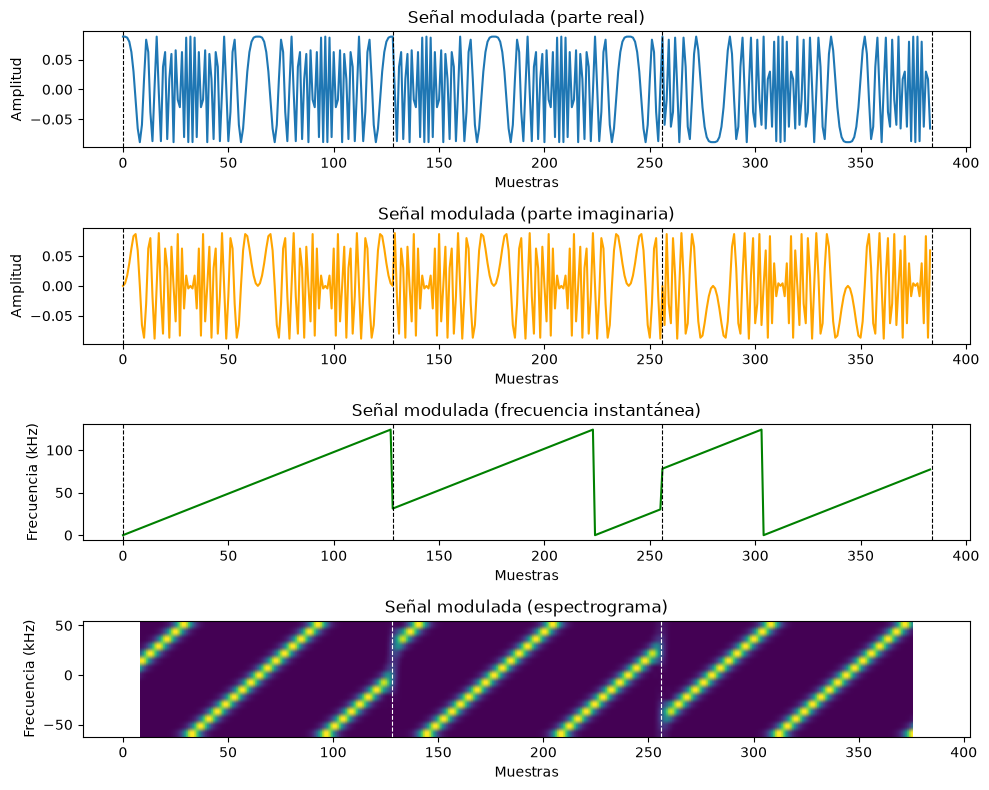

In [3]:
plots.modulated_signal(c, symbols, p);

**Dominio del tiempo**:
- La señal es una exponencial compleja de frecuencia variable, conocida como *chirp*.
- La parte real es una onda cosenoidal de frecuencia creciente, mientras que la parte imaginaria es una onda senoide de frecuencia creciente.

**Frecuencia instantánea**:
- El gráfico muestra la frecuencia instantánea de la señal de la Ec. 2. con fines pedagógicos.
- De acuerdo con lo que se puede ver en las ondas de la parte real e imaginaria, la frecuencia instantánea es una función lineal del tiempo, que aumenta de 0 a $B$ en el intervalo de tiempo $T_s$.
- La frecuencia instantánea inicial para cada símbolo es distinta de acuerdo a $f_0 = \frac{B}{2^{SF}} s(nT_s)$.

**Espectrograma:**
- Muestra la frecuencia real de $c$.

## Recepción

El módulo receptor se compone de un demodulador y un decodificador.

### Demodulación

Se conoce a esta etapa como *n-Tuple former* o conformador de tuplas, y genera símbolos a partir de la señal recibida, la cual es un vector complejo unidimensional de $2^{SF}$ chips por cada símbolo $n$.

Se analizará primero demodulando la señal modulada, y luego sumándole ruido blanco gaussiano aditivo (AWGN) para simular la transmisión por un canal ruidoso.

El proceso de demodulación de forma computacionalmente eficiente se describe en Ec. 16 como la proyección de la señal recibida $r(nT_s + kT)$ sobre un conjunto de *chirps* ortogonales $c|_{q}$:

$$
\langle r, c|_{s=q} \rangle = \sum_{k=0}^{2^{SF}-1} r(nT_s + kT)\, e^{-j2\pi \frac{k^2}{2^{SF}}} \cdot \frac{1}{\sqrt{2^{SF}}}\, e^{-j2\pi \frac{qk}{2^{SF}}}
$$

Se puede interpretar como la correlación entre la señal recibida y todos los *chirps* posibles, siendo el *chirp* que maximiza la proyección el símbolo recibido.

El término $e^{-j2\pi \frac{k^2}{2^{SF}}}$ se conoce como *down-chirp*. El resultado $d(nT_s + kT) = r(nT_s + kT) \cdot e^{-j2\pi \frac{k^2}{2^{SF}}}$ es una exponencial compleja de frecuencia constante igual a la frecuencia inicial del símbolo recibido. Se utiliza la transformada rápida de Fourier (FFT).

Luego, la transformada de Fourier de $d(nT_s + kT)$ resultará en un impulso desplazado en el índice de la frecuencia correspondiente a la frecuencia del símbolo recibido.


#### Visualización del proceso de decisión

Para cada símbolo recibido se obtiene la frecuencia inicial del *chirp* recibido mediante el *down-chirp* y la FFT. La transformada de Fourier de $d(nT_s + kT)$ (una exponencial compleja de frecuencia constante) resultará en un impulso desplazado en el índice de la frecuencia correspondiente a la frecuencia del símbolo recibido.

Mas adelante se analizará la decisión en un canal ruidoso.

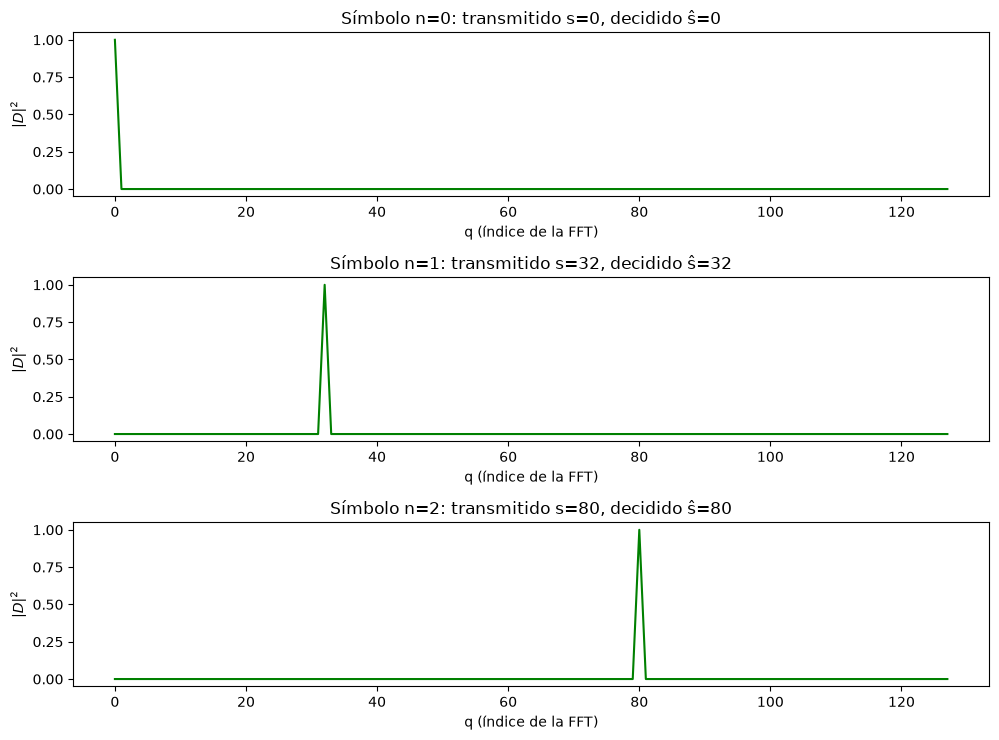

In [4]:
# Salida de la FFT del demodulador antes de decidir
D = rx.dechirp_fft(c, p)
symbols_rx = rx.demodulator(c, p)

plots.fft_decision(D, symbols, symbols_rx);

### Decodificación

Se descompone cada símbolo en un arreglo de $SF$ bits de acuerdo a Ec. 1.

## Cálculo del Bit Error Rate (BER)

El BER se calcula comparando el conjunto de bits transmitidos con el conjunto de bits recibidos. Se considera un bit erróneo si el bit recibido es distinto al bit transmitido.

Ya que aún no hemos introducido ruido en el canal, esperamos que el BER sea 0.

In [5]:
# Simular una transmisión completa de 100 símbolos aleatorios
bits_tx = rng.integers(0, 2, size=p.SF * 100)
bits_rx = rx.decoder(rx.demodulator(tx.modulator(tx.encoder(bits_tx, p), p), p), p)
print(f"Bit Error Rate (BER): {metrics.BER(bits_tx, bits_rx):.4f}")

# En caso de corromper un bit:
bits_rx[0] ^= 1  # bit flip
print(f"Bit Error Rate (BER) con un bit corrupto: {metrics.BER(bits_tx, bits_rx):.4f}")

Bit Error Rate (BER): 0.0000
Bit Error Rate (BER) con un bit corrupto: 0.0014


## Potencia de la señal modulada

In [6]:
for SF in [7, 2]:
    q = LoRaParams(SF=SF, B=125e3)
    P = metrics.power(tx.modulator(np.array([0]), q))
    print(f"Potencia de la señal modulada con SF={SF}, B={q.B / 1e3:.0f} kHz: {P:.4f}")

Potencia de la señal modulada con SF=7, B=125 kHz: 0.0078
Potencia de la señal modulada con SF=2, B=125 kHz: 0.2500


## Modelo de canal ruidoso

El canal dos distorsiones significativas sobre la señal transmitida $c(nT_s + kT)$: atenuación y desplazamiento. Esto se puede modelar con la respuesta al impulso del canal como sistema SLIT.

Luego, a la señal distorsionada se le suma ruido blanco gaussiano aditivo (AWGN) para simular la transmisión por un canal ruidoso.

In [7]:
# Transmisión de 100 símbolos aleatorios por un canal plano
SNR_dB = -10
ber = simulation.transmission_ber(p, SNR_dB, channel.FLAT)
print(f"Bit Error Rate (BER) con SNR={SNR_dB}dB: {ber:.4f}")

Bit Error Rate (BER) con SNR=-10dB: 0.0014


### Detección con ruido en un canal plano

Se repite la simulación de la transmisión y recepción de símbolos, pero esta vez se introduce ruido blanco gaussiano aditivo (AWGN) en el canal.

El canal es plano, es decir, respuesta en frecuencia constante.

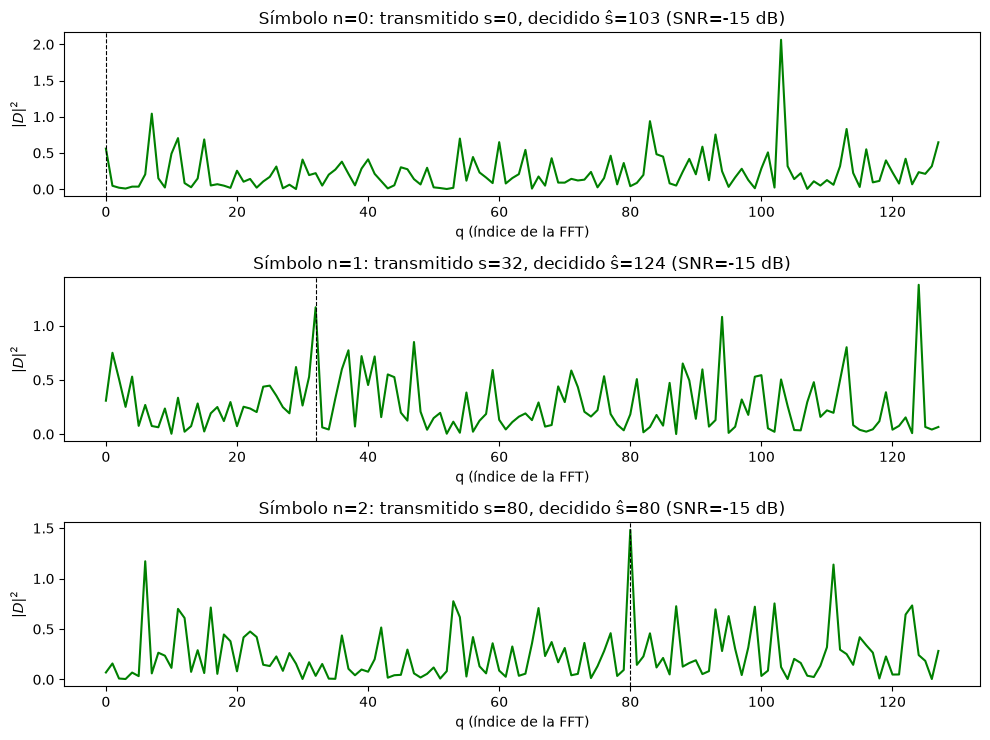

In [8]:
# Probar distintos SNR para ver cuándo empieza a fallar la decisión
SNR_dB = -15
c = tx.modulator(symbols, p)
r = channel.system(c, channel.FLAT, channel.noise_from_SNR(c, SNR_dB))

plots.fft_decision(rx.dechirp_fft(r, p), symbols, rx.demodulator(r, p), SNR_dB);

### Detección con ruido en un canal selectivo en frecuencia

Un canal no plano es selectivo en frecuencia. La respuesta al impulso del sistema usado para modelar un canal multicaminos es:

$$
h[n] = \sqrt{0.8}\,\delta[n] + \sqrt{0.2}\,\delta[n-1]
$$



### Performance de detección

Se analiza el BER vs SNR para el sistema simulado, el cual corresponde a la curva "Flat FSCM" de Fig. 1.

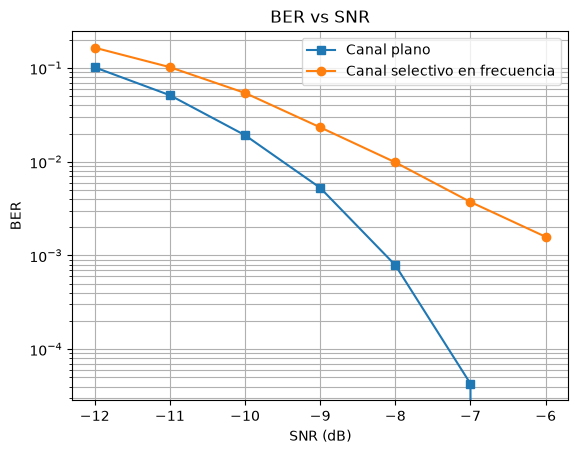

In [9]:
SNRs_dB = np.arange(-12.0, -5.0)  # -12 a -6 dB
simulations = 500  # Transmisiones de 100 símbolos por SNR

bers = {
    "Canal plano": simulation.ber_vs_snr(p, SNRs_dB, channel.FLAT, simulations),
    "Canal selectivo en frecuencia": simulation.ber_vs_snr(
        p, SNRs_dB, channel.FREQ_SELECTIVE, simulations
    ),
}
plots.ber_vs_snr(SNRs_dB, bers);

**Observaciones**:
- En el canal plano el BER cae de $0.1$ a $4 \cdot 10^{-5}$ entre $-12$ y $-7$ dB.
- El canal selectivo en frecuencia necesita más SNR para el mismo BER, y la diferencia crece con el SNR. El eco no se comporta como ruido, porque después del *down-chirp* concentra el 20 % de la potencia en el bin $s - 2$, un competidor fijo del bin del símbolo, y al ruido le alcanza con acercar esos dos bins en lugar de levantar un bin vacío.

## Detección de una trama

En esta sección se analiza el problema de detectar una trama en un canal ruidoso del lado del receptor: decidir si llegó una trama y en qué muestra empieza (sincronización). La trama es un preámbulo de 8 *up-chirps* (símbolos 0) y 2.25 *down-chirps*, seguido del *payload*. Antes de la trama el receptor solo recibe ruido, y no sabe cuándo empieza.

Se plantean tres métodos:

1. **Correlación con el preámbulo completo** (tiempo): filtro adaptado con los 8 *up-chirps*, integración coherente.
2. **Búsqueda de 8 picos** (tiempo): correlación móvil con un solo *up-chirp*, sumando la energía de 8 picos separados un símbolo. Integración no coherente.
3. **Demodulación del preámbulo** (frecuencia): se demodula cada ventana y se cuentan las decididas como símbolo 0.

Para cada método se presenta el estadístico, su umbral de Neyman-Pearson y su aplicación a una trama de ejemplo. Al final se comparan los tres métodos con la detección del inicio, la curva ROC y el *Frame Error Rate* (FER).

### Escenario y herramientas comunes

**Parámetros**: desde acá se usa $SF = 8$ y un *payload* de 10 símbolos. Con $SF = 8$ cada símbolo tiene el doble de muestras que con $SF = 7$ y, a igual SNR por muestra, 3 dB más de energía, lo que deja el error del *payload* lo bastante bajo a $-10$ dB para ver el efecto de la detección. El receptor escucha 5 símbolos de solo ruido antes de la trama. Cada método se aplica primero a una trama de ejemplo en el canal plano a $-10$ dB, y después se evalúa en función del SNR en el canal plano y en el selectivo en frecuencia.

**Umbral**: los tres métodos fijan el umbral con el criterio de Neyman-Pearson para la misma probabilidad de falsa alarma por símbolo, $P_{FA}$. Su valor sale de la tasa de falsas alarmas que tolera el receptor, porque cada falsa alarma hace que intente demodular una trama que no existe y, mientras tanto, puede perder una real. El receptor evalúa $B / 2^{SF}$ símbolos por segundo, así que para tolerar $R_{FA}$ falsas alarmas por segundo

$$
P_{FA} = R_{FA}\, \frac{2^{SF}}{B}
$$

Con una falsa alarma por minuto, $R_{FA} = 1/60\ \text{s}^{-1}$, resulta $P_{FA} \approx 3.4 \cdot 10^{-5}$ por símbolo. Se asume que el receptor conoce la potencia del ruido $\sigma^2$, que en la práctica se estima mientras no hay señal.

**Métricas**:

- **Inicio correcto**: fracción de tramas cuyo inicio se detecta en la muestra exacta. Una detección temprana (falsa alarma), una tardía o la no detección (*miss*) cuentan como error.
- **Frame Error Rate (FER)**: fracción de tramas con algún error. En un sistema que transmite tramas, si un solo bit del *payload* es incorrecto la trama se descarta (en la práctica lo detecta un CRC), así que el FER mide el sistema completo, detección y demodulación juntas.

In [ ]:
# Escenario para analizar las estrategias de detección
p = LoRaParams(SF=8, B=125e3)
num_symbols = 10  # Símbolos del payload
SNR_dB = -10
gap = 5  # Símbolos de silencio antes de la trama: desconocido para el receptor
symbols_tx = rng.integers(0, p.M, size=num_symbols)
R_FA = 1 / 60  # Tasa de falsas alarmas tolerable: una por minuto
P_FA = R_FA * p.Ts  # Probabilidad de falsa alarma por símbolo

r = channel.transmit_frame(symbols_tx, gap, p, SNR_dB, channel.FLAT)
r_clean = channel.transmit_frame(symbols_tx, gap, p, 100, channel.FLAT)  # Sin ruido apreciable
noise_power = channel.noise_power(p, SNR_dB)  # sigma^2, conocida por el receptor

plots.frame_structure(r, symbols_tx, gap, p, SNR_dB);

### Detección en el tiempo: correlación móvil con un up-chirp

En el tiempo el receptor no necesita sincronía de símbolo: desliza una plantilla conocida sobre la señal recibida, muestra a muestra, y busca dónde se parece más. La muestra $k$ donde se decide $H_1$ es a la vez la detección y la sincronización, porque es donde empieza la trama.

Para cada muestra $k$ se plantea un test de hipótesis binario:

- $H_0$: el preámbulo no empieza en la muestra $k$. Se recibe solo ruido, u otra parte de la trama.
- $H_1$: el preámbulo empieza en la muestra $k$, y $r_k = p + w$, donde $r_k$ son las muestras recibidas a partir de $k$, $p$ son los 8 *up-chirps* del preámbulo (conocidos) y $w$ es ruido gaussiano i.i.d.

Los dos métodos parten de la correlación móvil de la señal recibida con un solo *up-chirp* (símbolo 0):

$$
y[k] = \langle r_k, c|_{s=0} \rangle = \sum_{i=0}^{2^{SF}-1} r(kT + iT)\, c^*(iT)|_{s=0}
$$

Dentro del preámbulo, $|y[k]|^2$ es máxima cuando la plantilla queda alineada con un *up-chirp*, y nula con cualquier otro desplazamiento, porque un *up-chirp* desplazado en el tiempo es un *up-chirp* con un corrimiento de frecuencia, ortogonal al original.

Los picos aparecen cada $2^{SF}/2$ muestras y no cada $2^{SF}$. La frecuencia instantánea graficada en *Análisis de la señal modulada* va de 0 a $B$, pero la derivada de la fase de la Ec. 2, $2\pi k^2 / 2^{SF}$ para el símbolo 0, barre de 0 a $2B$ y, muestreada a $B$, se repliega. Cada *up-chirp* son dos copias de un *chirp* de $2^{SF}/2$ muestras, y el preámbulo produce 16 picos.

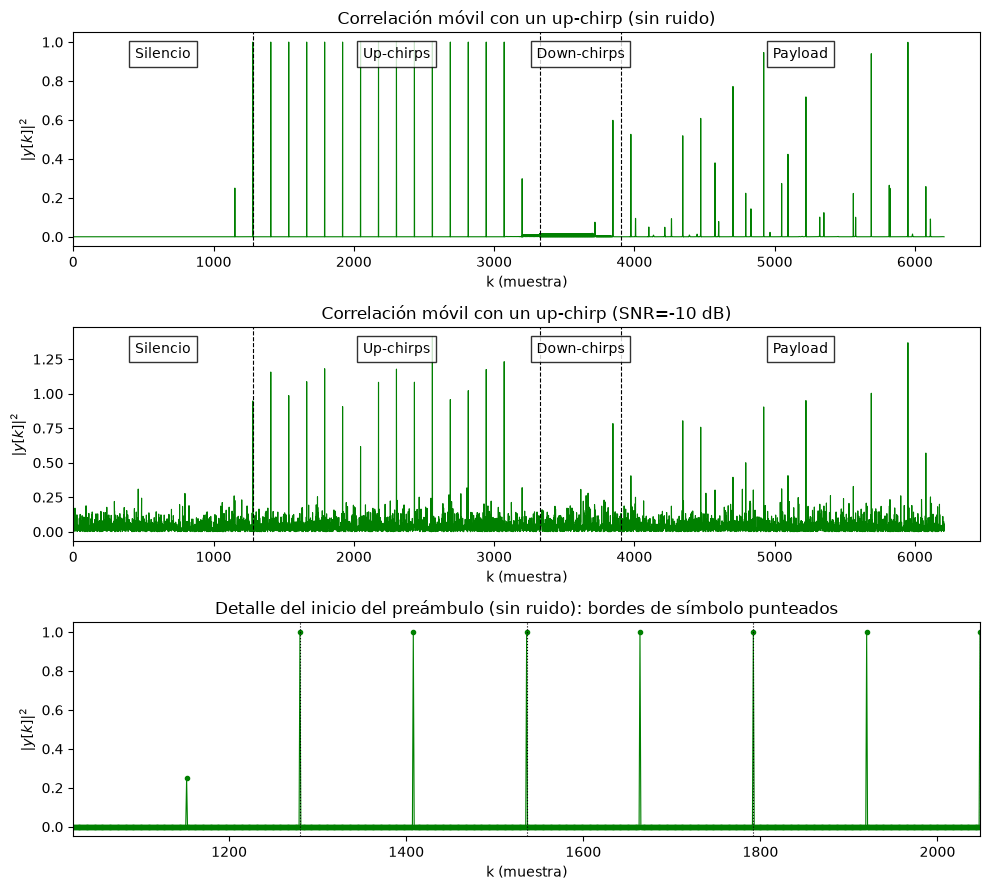

In [12]:
# Correlación móvil con un up-chirp sobre la trama del escenario, sin ruido y con ruido
y_clean = detection.upchirp_correlation(r_clean, p)
y = detection.upchirp_correlation(r, p)

plots.upchirp_correlation(y_clean, y, gap, p, SNR_dB);

**Observaciones**:
- Sin ruido se ve la estructura de la trama: picos de altura 1 cada $2^{SF}/2$ muestras durante los *up-chirps*, nada en el silencio ni en los *down-chirps*, y picos aislados en el *payload* (donde un símbolo, o una mezcla de dos símbolos consecutivos, se parece a un *up-chirp*).
- Con ruido los picos del preámbulo siguen sobresaliendo, pero el ruido también produce picos: decidir con uno solo daría muchas falsas alarmas. Los dos métodos en el tiempo combinan los 8 picos que deja el preámbulo, separados un símbolo: uno en forma coherente y otro no coherente.

### Detección en el tiempo: correlación con el preámbulo completo

La plantilla es el preámbulo completo de 8 *up-chirps*, $p$. Es el problema de detectar una señal conocida en ruido gaussiano, donde el test de razón de verosimilitud se reduce a correlar la señal recibida con la señal conocida (filtro adaptado) y comparar con un umbral. Como la fase de la señal recibida es desconocida, se compara el módulo al cuadrado:

$$
T[k] = \left| \langle r_k, p \rangle \right|^2 = \left| \sum_{n=0}^{7} y[k + n\,2^{SF}] \right|^2 \;\underset{H_0}{\overset{H_1}{\gtrless}}\; \eta
$$

Como $p$ son *up-chirps* repetidos, correlar con $p$ es sumar los 8 picos de $y[k]$ separados un símbolo. La suma es coherente, antes del módulo, así que las amplitudes de la señal se suman en fase (potencia $\times 64$) mientras que las potencias del ruido se suman ($\times 8$), una ganancia de $10\log_{10} 8 \approx 9$ dB respecto de un solo pico. A cambio, necesita que la fase de la señal se mantenga durante los 8 símbolos, lo que un corrimiento de frecuencia entre transmisor y receptor impediría.

**Umbral (Neyman-Pearson)**: no se conocen las probabilidades *a priori* de $H_0$ y $H_1$, así que se fija la $P_{FA}$ tolerable. Cada *chirp* tiene energía 1, así que bajo $H_0$ cada $y[k + n\,2^{SF}]$ es gaussiano complejo de varianza $\sigma^2$, la suma de 8 tiene varianza $8\sigma^2$ y $T[k]$ tiene distribución exponencial de media $8\sigma^2$:

$$
P_{FA} = P(T[k] > \eta \mid H_0) = e^{-\eta / 8\sigma^2} \quad\Rightarrow\quad \eta = -8\sigma^2 \ln P_{FA}
$$

El test se repite en las $2^{SF}$ muestras de cada símbolo, así que para tener la misma tasa de falsas alarmas que un test por símbolo se usa $P_{FA} / 2^{SF}$ en cada muestra.

**Inicio de la trama**: cada $2^{SF}/2$ muestras la plantilla vuelve a alinearse con parte del preámbulo, así que alrededor del inicio $T[k]$ es un peine, con $T \approx 64\,(1 - j/16)^2$ cuando quedan $j$ medios *chirps* afuera. El primer cruce del umbral suele ser uno de estos picos laterales, antes del inicio, así que el inicio se estima como el máximo de $T[k]$ en los 8 símbolos siguientes al primer cruce.

In [ ]:
# Correlación con el preámbulo completo sobre el escenario
eta = detection.threshold("full", p, noise_power, P_FA)
T = detection.preamble_correlation(r, p)
start = detection.detect_start(T, eta, p.n_upchirps * p.M)

plots.full_preamble_detection(T, eta, start, gap, p, P_FA, SNR_dB);

### Detección en el tiempo: búsqueda de 8 picos

En lugar de un pico de la correlación con el preámbulo completo, se buscan los 8 picos seguidos, separados un tiempo de símbolo ($2^{SF}$ muestras), que deja el preámbulo en la correlación móvil con un solo *up-chirp*. El estadístico suma la energía de los 8 picos candidatos a partir de la muestra $k$:

$$
S[k] = \sum_{n=0}^{7} \left| y[k + n\,2^{SF}] \right|^2 \;\underset{H_0}{\overset{H_1}{\gtrless}}\; \eta_S
$$

La diferencia con $T[k]$ es dónde se toma el módulo. $T[k]$ suma los picos y después toma el módulo (integración coherente); $S[k]$ toma el módulo de cada pico y después suma (integración no coherente). Al sumar energías se descarta la fase de cada pico, así que el método tolera que la fase cambie entre símbolos. A cambio, el ruido de cada pico suma su energía en lugar de promediarse con el de los demás, y se espera que necesite más SNR que $T[k]$.

Los picos intermedios, a $2^{SF}/2$ muestras, no se usan. Con picos separados un símbolo las 8 correlaciones usan muestras disjuntas, y bajo $H_0$ son independientes.

**Umbral (Neyman-Pearson)**: bajo $H_0$ cada $y[k + n\,2^{SF}]$ es gaussiano complejo de varianza $\sigma^2$, así que $|y|^2$ es exponencial de media $\sigma^2$. Los 8 son independientes, por lo que $S[k]$ tiene distribución Gamma de orden 8 (Erlang) y escala $\sigma^2$, con cola en forma cerrada:

$$
P_{FA} = P(S[k] > \eta_S \mid H_0) = e^{-\eta_S/\sigma^2} \sum_{i=0}^{7} \frac{(\eta_S/\sigma^2)^i}{i!}
$$

$\eta_S$ no se puede despejar, pero como la cola es decreciente en $\eta_S$, se busca por bisección. Igual que en $T[k]$, se usa $P_{FA} / 2^{SF}$ por muestra.

**Inicio de la trama**: $S[k]$ también es un peine alrededor del inicio, y el inicio se estima de la misma forma. Sus picos laterales son más altos, relativos al principal, que los de $T[k]$. Con medio símbolo de error $S \approx 7.25$, contra 8 en el inicio, mientras que $T$ baja de 64 a $\approx 56$.

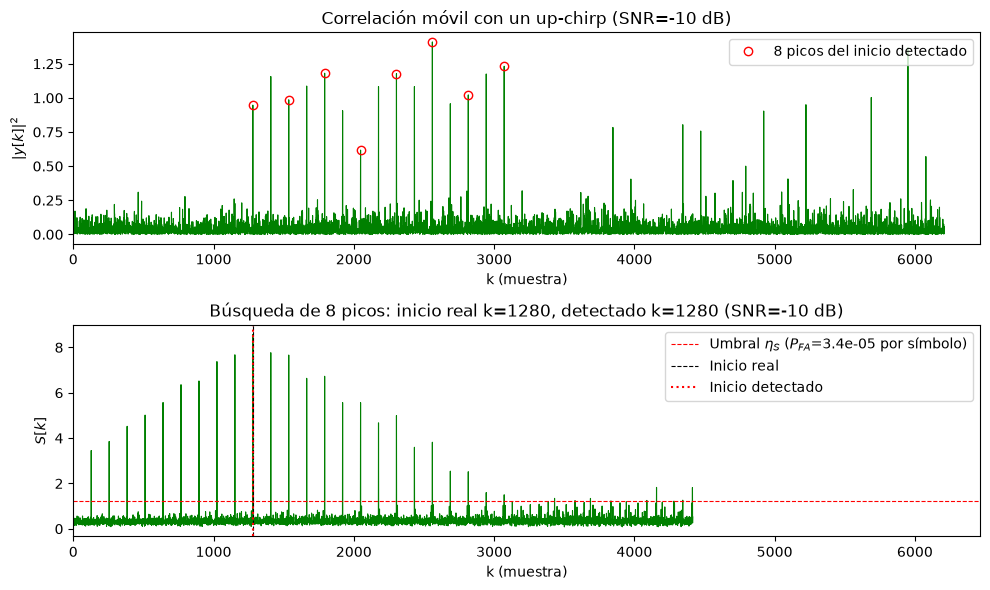

In [15]:
# Búsqueda de 8 picos sobre el escenario
eta_S = detection.threshold("peaks", p, noise_power, P_FA)
S = detection.peaks_statistic(r, p)
start = detection.detect_start(S, eta_S, p.n_upchirps * p.M)

plots.peaks_detection(y, S, eta_S, start, gap, p, P_FA, SNR_dB);

### Detección en frecuencia: demodulación del preámbulo

A diferencia de la detección en el tiempo, se asume sincronía de símbolo. El receptor divide la señal recibida en ventanas de $2^{SF}$ muestras alineadas con los bordes de los símbolos, y lo que no conoce es en qué ventana $m$ empieza la trama. Las hipótesis son las mismas que en el tiempo, por ventana en lugar de por muestra.

La estrategia en frecuencia reutiliza el demodulador (Ec. 16): cada ventana se multiplica por el *down-chirp* y se calcula su FFT. Durante el preámbulo cada ventana es un *up-chirp* de símbolo 0, por lo que el pico de la FFT aparece en el bin $q = 0$.

Mirar solo el bin 0 no aporta nada nuevo, porque $D_n[0]$ es la correlación móvil $y[k]$ de la detección en el tiempo evaluada en el borde de la ventana, $k = n\,2^{SF}$. La diferencia está en comparar el bin 0 con los demás bins en vez de con un umbral absoluto. El estadístico es la cantidad de ventanas, entre 8 consecutivas, en las que el demodulador decide el símbolo $\hat{s}[n] = 0$:

$$
V[m] = \sum_{n=m}^{m+7} \mathbb{1}\{\hat{s}[n] = 0\} \;\underset{H_0}{\overset{H_1}{\gtrless}}\; K
$$

Un umbral $K < 8$ tolera ventanas del preámbulo mal decididas por el ruido. El inicio se estima igual que en el tiempo: el máximo de $V[m]$ después del primer cruce.

**Umbral (Neyman-Pearson)**: bajo $H_0$ cada ventana es ruido blanco gaussiano, y su FFT (unitaria) también lo es, así que el máximo cae en cualquiera de los $2^{SF}$ bins con igual probabilidad y cada ventana se decide como símbolo 0 con probabilidad $p_0 = 2^{-SF}$. El ruido de ventanas distintas es independiente, por lo que $V[m]$ tiene distribución binomial $\mathcal{B}(8, p_0)$:

$$
P_{FA}(K) = P(V[m] \geq K \mid H_0) = \sum_{k=K}^{8} \binom{8}{k} p_0^k (1 - p_0)^{8-k}
$$

$V[m]$ es discreto, así que en general ningún $K$ da exactamente la $P_{FA}$ pedida. Bajar el umbral sube la $P_D$, por lo que Neyman-Pearson elige el menor $K$ con $P_{FA}(K) \leq P_{FA}$. Hay un test por ventana, así que $P_{FA}$ se usa sin dividir. Para $SF = 8$ y $P_{FA} \approx 3.4 \cdot 10^{-5}$, $P_{FA}(2) \approx 4.2 \cdot 10^{-4}$ no la respeta y $P_{FA}(3) \approx 3.3 \cdot 10^{-6}$ sí, así que $K = 3$, con una $P_{FA}$ unas 10 veces menor que la tolerada.

- **Ventaja**: el umbral no depende de $\sigma^2$, ya que la decisión de cada ventana es relativa entre bins y la distribución de $V[m]$ bajo $H_0$ solo depende de $SF$. No hace falta conocer ni estimar la potencia del ruido.
- **Desventaja**: cada ventana toma una decisión dura con la energía de un solo símbolo, y se pierde la ganancia de 9 dB de la suma coherente. Se espera que necesite más SNR que la detección en el tiempo.
- **Empates**: con probabilidad $2^{-SF}$ la ventana de ruido justo antes del preámbulo también se decide como símbolo 0, y $V[m]$ empata en 8 con el inicio real. Se elige la primera ventana del empate, un error de $\approx 0.4\%$ que no baja con el SNR. En el tiempo no hay empates, porque $T[k]$ es continuo.

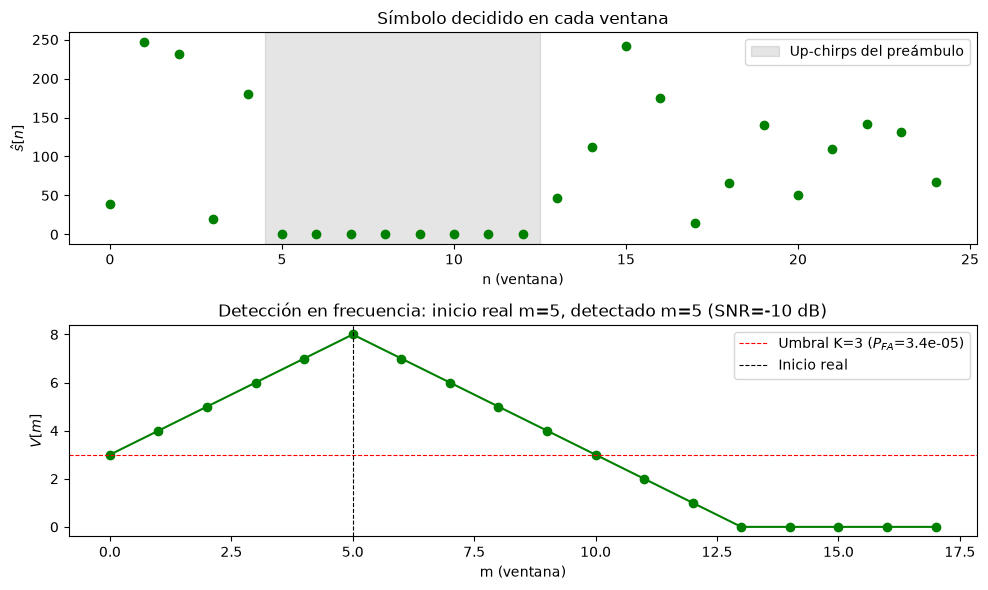

In [17]:
# Detección en frecuencia sobre el escenario
K = detection.threshold("freq", p, noise_power, P_FA)
V = detection.preamble_zero_count(r, p)
start = detection.detect_start(V, K, p.n_upchirps)

# Símbolo decidido en cada ventana, para ver qué ventanas cuentan en V[m]
symbols_rx = rx.demodulator(r[: r.size // p.M * p.M], p)

plots.freq_detection(symbols_rx, V, K, start, gap, p, P_FA, SNR_dB);

### Comparación de los métodos

#### Detección del inicio

Se simula la detección del inicio con los tres métodos en ambos canales, con 300 tramas por SNR. Junto con la ROC, es la métrica para comparar los detectores, porque $1 - P(\text{inicio correcto})$ es exactamente la fracción de tramas que se pierden por la detección o la sincronización, ya que en esta simulación un inicio corrido una sola muestra invalida el *payload*.

In [ ]:
SNRs_rates_dB = np.arange(-24.0, -3.0, 1.0)  # -24 a -4 dB
simulations = 300  # Tramas simuladas por SNR
detectors = {
    "full": detection.detect_full,
    "peaks": detection.detect_peaks,
    "freq": detection.detect_freq,
}

start_flat, start_sel = {}, {}
for method, detect in detectors.items():
    for start, h in ((start_flat, channel.FLAT), (start_sel, channel.FREQ_SELECTIVE)):
        start[method], _ = simulation.frame_rates(
            detect, SNRs_rates_dB, h, p, P_FA, simulations, num_symbols=num_symbols, gap=gap
        )

plots.compare_methods(
    SNRs_rates_dB,
    start_flat,
    start_sel,
    "P(inicio correcto)",
    "Detección del inicio de la trama vs SNR",
);

**Observaciones**:
- Orden de los métodos, en ambos canales: correlación con el preámbulo completo, búsqueda de 8 picos y demodulación del preámbulo, con unos 2 dB entre cada uno (50 % de aciertos cerca de $-20.5$, $-18.5$ y $-16.5$ dB en el canal plano).
- **Integración coherente contra no coherente**: los dos métodos en el tiempo usan los mismos 8 picos de $y[k]$. Sumarlos antes del módulo (preámbulo completo) gana unos 2 dB frente a sumar sus energías (8 picos), a cambio de necesitar que la fase se mantenga durante el preámbulo.
- **Decisión blanda contra decisión dura**: los métodos en el tiempo conservan cuánto se parece cada posición a un *up-chirp*. La demodulación reduce cada ventana a "símbolo 0 o no", perdiendo información, y además necesita sincronía de símbolo.
- El canal selectivo desplaza todas las curvas $\approx 1$ dB sin cambiar el orden. La plantilla solo captura el camino principal, que lleva el 80 % de la energía ($10\log_{10} 0.8 \approx -1$ dB).
- La demodulación del preámbulo no llega al 100 % ni a SNR alto, por los empates descriptos en la detección en frecuencia ($\approx 0.4\%$).

#### Curva ROC

La detección del inicio mezcla detección y localización. Para comparar los métodos solo como detectores se usa el test binario en una posición (una muestra en el tiempo, una ventana en frecuencia):

- $H_0$: los 8 símbolos a partir de la posición contienen solo ruido.
- $H_1$: la posición está alineada con el inicio del preámbulo.

Cada umbral define un punto de operación ($P_{FA}$, $P_D$), con $P_D = P(\text{'}H_1\text{'} \mid H_1)$. La curva ROC (*Receiver Operating Characteristic*) recorre todos los umbrales y muestra el compromiso entre ambas probabilidades, ya que subir el umbral reduce las falsas alarmas a costa de perder detecciones. Neyman-Pearson elige el punto de la curva con la mayor $P_D$ que respeta la $P_{FA}$ tolerable (estrellas), y un detector es mejor que otro si su curva queda por encima.

El eje es la $P_{FA}$ por símbolo. En el tiempo se prueban $2^{SF}$ posiciones por símbolo, así que su tasa de falsas alarmas por símbolo es $2^{SF}$ veces la $P_{FA}$ por muestra, y con este eje los tres métodos se comparan a la misma tasa. Como la distribución de cada estadístico bajo $H_0$ es conocida, la $P_{FA}$ se calcula con el umbral y solo se estima $P_D$. Las curvas empíricas (punteadas), que estiman también la $P_{FA}$, validan las teóricas donde se pueden medir. La curva de la detección en frecuencia es una escalera, porque $V[m]$ solo toma 9 valores.

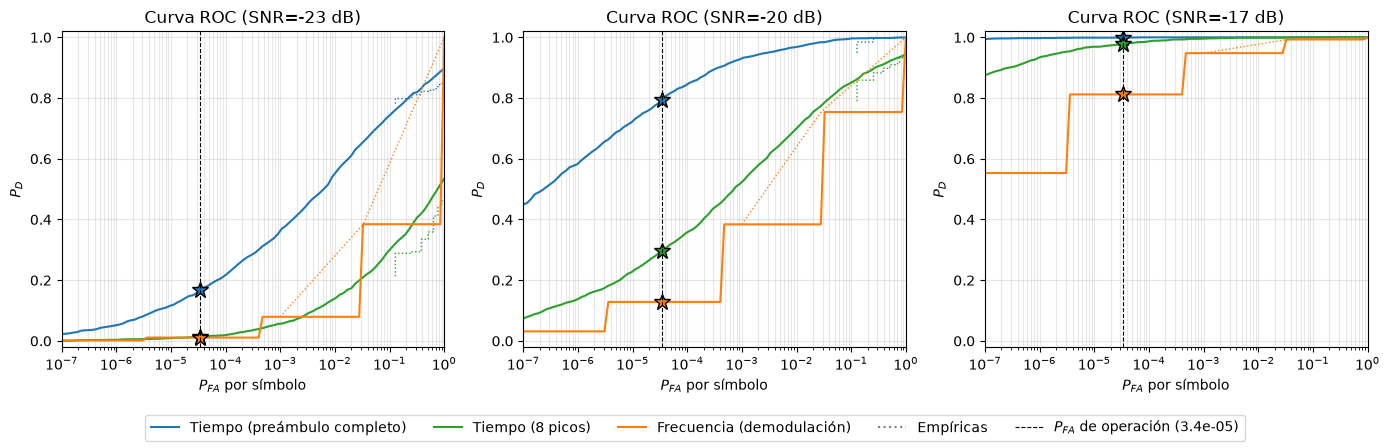

In [21]:
SNRs_roc_dB = [-23.0, -20.0, -17.0]  # Un gráfico por SNR, en el rango donde cambia la detección
simulations_roc = 2000  # Realizaciones por hipótesis
P_FA_axis = np.logspace(-7, 0, 100)  # P_FA por símbolo

roc_curves = {
    SNR: simulation.roc_curves(p, SNR, simulations_roc, P_FA_axis, P_FA) for SNR in SNRs_roc_dB
}
plots.roc(roc_curves, P_FA_axis, P_FA);

**Observaciones**:
- En el punto de operación, a $-20$ dB, la correlación con el preámbulo completo detecta con $P_D \approx 0.8$, la búsqueda de 8 picos con $\approx 0.3$ y la demodulación con $\approx 0.12$. La correlación con el preámbulo completo queda por encima de las demás para cualquier $P_{FA}$ y SNR.
- Entre la búsqueda de 8 picos y la demodulación el orden depende de la $P_{FA}$. Con $P_{FA}$ altas y SNR bajo la demodulación puede superar a la búsqueda de 8 picos, porque prueba una sola posición por símbolo y necesita un umbral más bajo para la misma tasa de falsas alarmas.
- En la demodulación la $P_D$ cae a escalones: con 9 umbrales posibles, la $P_{FA}$ de operación obliga a $K = 3$.
- El test en una posición funciona a menor SNR que la detección del inicio (a $-20$ dB, $P_D \approx 0.8$ contra $\approx 0.6$ de inicio correcto con la correlación con el preámbulo completo), porque encontrar el inicio exige además que la posición correcta supere a las vecinas.

#### Frame Error Rate (FER)

El FER mide el sistema completo, porque una trama se pierde si falla la detección del preámbulo o la demodulación del *payload*. Por eso no sirve para comparar los detectores entre sí, sino para saber si la detección limita al sistema. Para eso se compara el FER de cada método con el de una detección ideal que conoce el inicio de la trama, con $FER_{ideal}$ debido solo a errores de demodulación. El ruido del preámbulo y el del *payload* son independientes, así que

$$
FER = 1 - P(\text{inicio correcto})\,(1 - FER_{ideal})
$$

y donde el *payload* falla igual ($FER_{ideal} \approx 1$), el FER oculta las fallas de detección.

El FER cae varios órdenes de magnitud en pocos dB, así que el eje es logarítmico. Cada SNR se simula hasta juntar 30 tramas con error o llegar a 2000 tramas, así que el FER más chico que se puede medir es $1/2000 = 5 \cdot 10^{-4}$. Los puntos sin errores no se dibujan.

In [ ]:
SNRs_fer_dB = np.arange(-14.0, -5.0, 1.0)  # -14 a -6 dB
# Referencia: detección ideal, solo hay errores de demodulación
detectors_fer = {**detectors, "ideal": detection.ideal_detector(gap)}

fer_flat, fer_sel = {}, {}
for method, detect in detectors_fer.items():
    for fer, h in ((fer_flat, channel.FLAT), (fer_sel, channel.FREQ_SELECTIVE)):
        _, fer[method] = simulation.frame_rates(
            detect, SNRs_fer_dB, h, p, P_FA, 2000, num_symbols=num_symbols, gap=gap, min_errors=30
        )

plots.compare_methods(
    SNRs_fer_dB,
    fer_flat,
    fer_sel,
    "FER",
    f"FER vs SNR ({num_symbols} símbolos de payload)",
    logy=True,
);

**Observaciones**:
- En el canal plano los métodos en el tiempo no limitan al sistema: sus curvas coinciden con la de detección ideal dentro del error de la simulación. El FER lo pone el *payload*, $\approx 3 \cdot 10^{-3}$ a $-10$ dB y en el mínimo medible ($5 \cdot 10^{-4}$) a $-9$ dB.
- La demodulación del preámbulo tiene un piso de $\approx 4 \cdot 10^{-3}$ desde $-9$ dB, por los empates descriptos en la detección en frecuencia ($2^{-SF} \approx 0.4\%$). Es el único detector que limita al sistema a SNR alto.
- Por debajo de $-11$ dB el *payload* falla igual y oculta las fallas de detección, aunque los métodos difieren en hasta 4 dB en la detección del inicio.
- El canal selectivo empeora mucho el FER, también con detección ideal: $\approx 0.13$ a $-10$ dB contra $3 \cdot 10^{-3}$ en el plano. Es la misma penalidad del eco que en el BER (ver *Performance de detección*).

## Prueba en el SDR

Hasta acá el receptor se evaluó por simulación. En este capítulo se prueba con un SDR (*software defined radio*), un equipo que transmite y recibe las muestras que genera y procesa la PC, en tres pasos:

1. **Loopback digital**: el SDR devuelve las muestras transmitidas sin pasar por el canal, y se verifica el software sin ruido.
2. **SNR y FER sin ruido agregado**: se mide el SNR del equipo con distintas potencias de transmisión, para saber si llega al rango donde cambia el FER.
3. **FER por el aire**: se agrega ruido en el TX para llegar a ese rango, y se compara el FER medido con la simulación.

Se usa un solo detector, la correlación con el preámbulo completo. Fue el de mejor desempeño en la simulación y, en el canal plano, no agrega errores respecto de la detección ideal (ver *Frame Error Rate (FER)*).

### Configuración del experimento

El SDR es un ADALM-Pluto del laboratorio, al que se accede por una VPN. El mismo equipo transmite (TX) y recibe (RX), así que ambos comparten el oscilador local y la señal llega sin corrimiento de frecuencia.

Se usan los mismos parámetros que en la sección del FER, $SF = 8$ y tramas de 10 símbolos de *payload*, con una portadora de 905 MHz. El ancho de banda es $B = 1$ MHz, con una muestra por chip. Como el SNR de la simulación es por muestra, la curva de FER vs SNR no depende de $B$, y el resultado vale también para los 125 kHz de LoRa.

El TX repite sin pausa un buffer de 50 tramas. Antes de cada trama hay un silencio de largo al azar, de 5 a 10 símbolos, para que el receptor no pueda predecir dónde empieza la siguiente. El RX graba una captura que contiene todas las tramas del buffer.

El receptor recorre la captura sin saber dónde están las tramas. En cada tramo busca un preámbulo con el detector y, si lo encuentra, demodula el *payload*. El umbral del detector se calcula con la potencia del ruido medida en los silencios, como si el receptor la estimara mientras el canal está libre. La medición, que sí conoce lo transmitido, ubica el buffer en la captura y compara cada trama con la que el receptor detectó más cerca de su inicio.

In [ ]:
import numpy as np

from lora import LoRaParams, channel, detection, plots, sdr, simulation

# False: usa las capturas guardadas en captures/ (no necesita el SDR ni la VPN)
# True: mide con el SDR del laboratorio y sobrescribe captures/
USE_SDR = False
URI = "ip:192.168.1.31" if USE_SDR else None

p_sdr = LoRaParams(SF=8, B=1e6)
num_symbols = 10  # Símbolos del payload
gap_range = (5, 10)  # Largo del silencio antes de cada trama, en símbolos
P_FA = 1 / 60 * p_sdr.Ts  # Una falsa alarma por minuto
N_FRAMES = 50  # Tramas por punto del FER
SNRs_air_dB = np.arange(-14.0, -8.0, 1.0)  # Donde el FER simulado pasa de casi 1 a casi 0

### Loopback digital

En loopback digital, el Pluto devuelve al RX las muestras del TX sin convertirlas en una señal analógica, así que no hay ruido ni canal. Se espera recibir todas las tramas sin error y con el inicio detectado en la muestra exacta, y cualquier error indica una falla del software.

In [ ]:
def run_loopback(pluto):
    symbols, gaps, r, _ = sdr.measure(pluto, p_sdr, 10, num_symbols, gap_range, calibrate=False)
    return r, {"symbols": symbols, "gaps": gaps}


r_loop, meta_loop = sdr.acquire("captures/loopback.npz", run_loopback, p_sdr, URI, loopback=1)
ev_loop = sdr.evaluate(r_loop, meta_loop["symbols"], meta_loop["gaps"], p_sdr, P_FA)
print(
    f"Loopback digital: {ev_loop.errors.sum()} de {ev_loop.errors.size} tramas con error, "
    f"{np.sum(ev_loop.timing == 0)} con el inicio detectado exacto"
)

**Observaciones**:
- *TODO: volver a medir (la captura es de la primera corrida en el laboratorio, con silencios fijos) y comentar si todas las tramas llegan sin error y con el inicio exacto.*

### SNR y FER sin ruido agregado

En la simulación, el FER pasa de casi 1 a casi 0 entre $-14$ y $-9$ dB de SNR (ver *Frame Error Rate (FER)*). Para saber si el equipo llega a ese rango, se transmiten 50 tramas con cada atenuación del TX y se miden el SNR y el FER. La ganancia del RX la elige el control automático de ganancia (AGC) del Pluto antes de cada captura, y después queda fija.

El SNR se estima comparando la captura con lo transmitido. Con el buffer transmitido $x$ y la captura $r$ alineada con él, ambos de $N$ muestras, la amplitud compleja $\hat a$ con que llega la señal se estima por mínimos cuadrados, y lo que queda al restar la señal es el ruido:

$$
\hat a = \frac{\langle x, r \rangle}{\langle x, x \rangle}, \qquad
\hat\sigma^2 = \frac{\| r - \hat a\, x \|^2}{N}, \qquad
SNR = \frac{|\hat a|^2 P_{trama}}{\hat\sigma^2}
$$

donde $P_{trama}$ es la potencia de la trama, la misma referencia que en la simulación. El ruido estimado $\hat\sigma^2$ incluye el ruido térmico del RX, la cuantización y la distorsión del equipo, todo lo que no es la señal transmitida.

Si el SNR queda por encima del rango aun con la máxima atenuación, hace falta agregar ruido en el TX.

In [ ]:
ATTENS_dB = np.array([-10.0, -30.0, -50.0, -70.0, -89.0])


def run_atten(pluto):
    runs = []
    for atten_dB in ATTENS_dB:
        sdr.set_tx_atten(pluto, atten_dB)
        runs.append(sdr.measure(pluto, p_sdr, N_FRAMES, num_symbols, gap_range))
    return sdr.stack(runs, attens_dB=ATTENS_dB)


c_att, meta_att = sdr.acquire("captures/atten.npz", run_atten, p_sdr, URI)
evs_att = sdr.evaluate_all(c_att, meta_att, p_sdr, P_FA)
for atten_dB, gain, ev in zip(meta_att["attens_dB"], meta_att["gain"], evs_att):
    print(
        f"Atenuación {atten_dB:4.0f} dB: ganancia {gain:2.0f} dB, SNR {ev.snr:5.1f} dB, "
        f"FER {ev.errors.mean():.2f}, inicio exacto en {np.sum(ev.timing == 0)} de {ev.errors.size}"
    )
plots.snr_vs_atten(meta_att["attens_dB"], np.array([ev.snr for ev in evs_att]), SNRs_air_dB);

**Observaciones**:
- *TODO: medir (hoy se usa el Pluto simulado, que no tiene ruido térmico, y por eso el SNR no cambia con la atenuación) y decidir con el resultado si hace falta agregar ruido.*

### FER por el aire

Para llevar el SNR al rango del FER, se suma ruido blanco gaussiano a las muestras antes de transmitirlas, con el mismo modelo que la simulación y una potencia fijada respecto de la potencia de la trama. En el RX se le suma el ruido del equipo, así que cada punto se grafica con el SNR medido y no con el agregado.

El FER medido se compara con el simulado en el canal plano, con el mismo detector y los mismos parámetros. Se espera que los puntos queden sobre la curva simulada. Si quedaran a la derecha (más SNR para el mismo FER), la diferencia sería una pérdida del equipo real. Con 50 tramas por punto, el menor FER que se puede medir es $1/50$, y un punto sin errores no se puede dibujar en escala logarítmica.

La primera figura muestra el espectro de una captura y los *up-chirps* del preámbulo después del *dechirp* (multiplicar por el *down-chirp* y calcular la FFT, como en el demodulador).

In [ ]:
def run_air(pluto):
    runs = [
        sdr.measure(pluto, p_sdr, N_FRAMES, num_symbols, gap_range, SNR_dB)
        for SNR_dB in SNRs_air_dB
    ]
    return sdr.stack(runs, SNRs_tx_dB=SNRs_air_dB)


c_air, meta_air = sdr.acquire("captures/air.npz", run_air, p_sdr, URI)
evs_air = sdr.evaluate_all(c_air, meta_air, p_sdr, P_FA)
for SNR_tx, gain, r, ev in zip(meta_air["SNRs_tx_dB"], meta_air["gain"], c_air, evs_air):
    print(
        f"SNR agregado {SNR_tx:5.1f} dB: SNR medido {ev.snr:5.1f} dB, ganancia {gain:2.0f} dB, "
        f"pico {sdr.adc_peak(r) / sdr.ADC_FULL_SCALE:4.0%} del rango del ADC, "
        f"FER {ev.errors.mean():.2f}"
    )

timing = np.concatenate([ev.timing for ev in evs_air])
values, counts = np.unique(timing, return_counts=True)
print("Error del inicio detectado (muestras: tramas):", dict(zip(values.tolist(), counts.tolist())))

# Captura con el SNR más alto
plots.sdr_capture(c_air[-1], evs_air[-1].starts[0], p_sdr);

In [ ]:
# Referencia: FER simulado en canal plano con el mismo detector y los mismos parámetros
SNRs_sim_dB = np.arange(-15.0, -7.0, 1.0)
_, fer_sim = simulation.frame_rates(
    detection.detect_full,
    SNRs_sim_dB,
    channel.FLAT,
    p_sdr,
    P_FA,
    500,
    num_symbols=num_symbols,
    gap=gap_range[0],
    min_errors=30,
)
plots.fer_sdr(
    SNRs_sim_dB,
    fer_sim,
    np.array([ev.snr for ev in evs_air]),
    np.array([ev.errors.mean() for ev in evs_air]),
    N_FRAMES,
);

**Observaciones**:
- *TODO: volver a medir con 50 tramas por punto y silencios al azar (la captura es de la primera corrida en el laboratorio, con 20 tramas por punto), comparar con la simulación y comentar el espectro y el *dechirp*.*